<a href="https://colab.research.google.com/github/wzy34/colab_projects/blob/main/names_mlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A MLP approach of generating names
Based on [A Neural Probabilistic Language Model](http://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf)

In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

## Dataset preparation

In [2]:
words = open("/content/drive/MyDrive/names.txt").read().splitlines()
words[:5]

['emma', 'olivia', 'ava', 'isabella', 'sophia']

In [3]:
len(words)

32033

In [4]:
chars = sorted(list(set("".join(words))))
stoi = {char:i + 1 for i, char in enumerate(chars)}
stoi['.'] = 0
print(stoi)
itos = {i+1:s for i, s in enumerate(chars)}
itos[0] = '.'
print(itos)

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, '.': 0}
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [7]:
def build_dataset(words, block_size):
  X, Y = [], []
  for w in words:
    #print(w)
    context = [0] * block_size
    for c in w + '.':
      ix = stoi[c]
      X.append(context)
      Y.append(ix)
      #print("".join(itos[i] for i in context), "---->", itos[ix])
      # perform like a sliding window
      context = context[1:] + [ix]
  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))
X_train, Y_train = build_dataset(words[:n1], 3)
Xdev, Ydev = build_dataset(words[n1:n2], 3)
Xte, Yte = build_dataset(words[n2:], 3)

torch.Size([182388, 3]) torch.Size([182388])
torch.Size([22769, 3]) torch.Size([22769])
torch.Size([22989, 3]) torch.Size([22989])


In [8]:
print(Xte)
print(Yte)

tensor([[ 0,  0,  0],
        [ 0,  0, 10],
        [ 0, 10,  1],
        ...,
        [12,  9, 14],
        [ 9, 14, 21],
        [14, 21, 19]])
tensor([10,  1, 14,  ..., 21, 19,  0])


## Build look-up table C in the paper

**Look up table can also be considered as the first layer of a neural network**

## Forward pass

In [10]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [11]:
sum(p.nelement() for p in parameters)

11897

In [12]:
for p in parameters:
  p.requires_grad = True

In [25]:
stepi = []
lossi = []
for i in range(1000):
  ix = torch.randint(0, X_train.shape[0], (32, ))
  emb = C[X_train[ix]]
  h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Y_train[ix])
  for p in parameters:
    p.grad = None
  loss.backward()
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad
  stepi.append(i)
  lossi.append(loss.item())
print(loss.item())

2.458704948425293


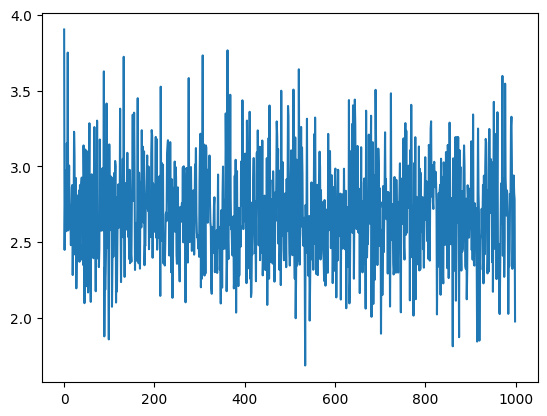

In [23]:
plt.plot(stepi, lossi)

In [26]:
block_size = 3
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)
for _ in range(20):
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    print(''.join(itos[i] for i in out))

carmah.
ado.
hevin.
jari.
hea.
caslanden.
jazonen.
apdry.
caideni.
ara.
ara.
chaiir.
aslei.
pelle.
peir.
edin.
zarou.
tai.
adbi.
wetteog.
